Khám phá dữ liệu (EDA)

C:\Users\Hi Windows 11\AppData\Local\Temp\ipykernel_21376\1006272089.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='quality', data=df, palette='viridis')


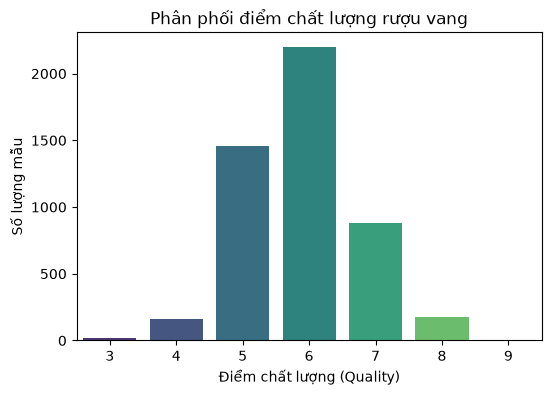

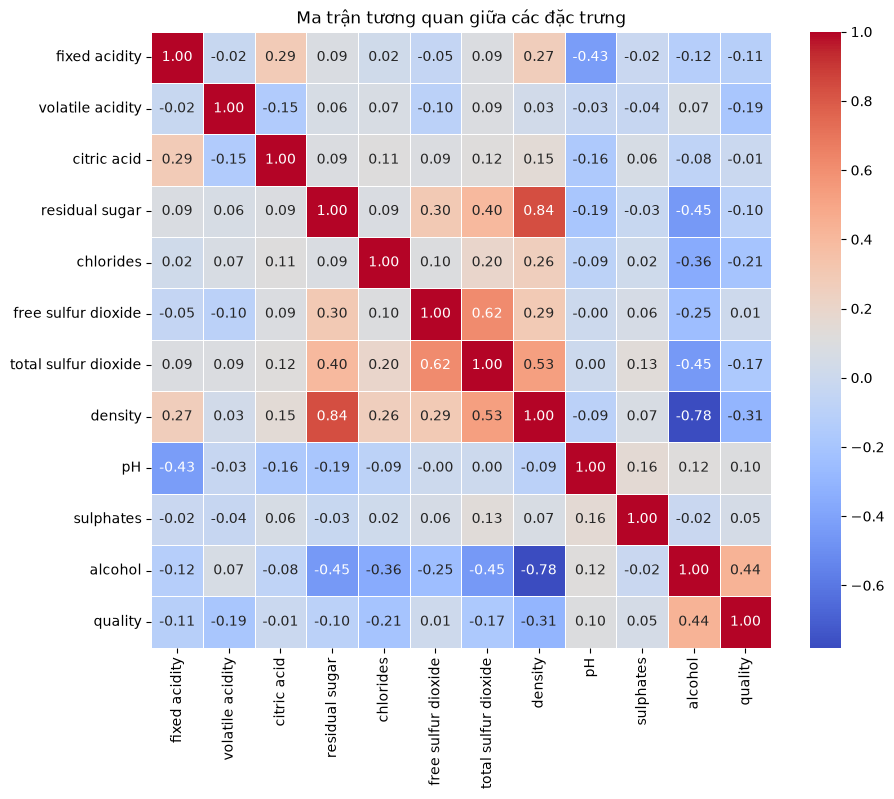

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Vẽ biểu đồ phân phối điểm chất lượng rượu (quality)
plt.figure(figsize=(6, 4))
sns.countplot(x='quality', data=df, palette='viridis')
plt.title('Phân phối điểm chất lượng rượu vang')
plt.xlabel('Điểm chất lượng (Quality)')
plt.ylabel('Số lượng mẫu')
plt.show()

# 2. Vẽ ma trận tương quan (Correlation Heatmap) để xem yếu tố nào tác động mạnh nhất
plt.figure(figsize=(10, 8))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Ma trận tương quan giữa các đặc trưng')
plt.show()

Tiền xử lý Dữ liệu và Chia tập Train / Test

In [3]:
# Tách biến đặc trưng (X) và biến mục tiêu (y)
X = df.drop(columns=['quality'])
y = df['quality']

# Chia tỷ lệ 80% cho tập huấn luyện (train) và 20% cho tập kiểm thử (test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Chuẩn hóa dữ liệu (Lưu ý: Chỉ fit_transform trên tập Train, chỉ transform trên tập Test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Kích thước tập huấn luyện (Train):", X_train_scaled.shape)
print("Kích thước tập kiểm thử (Test):", X_test_scaled.shape)

Kích thước tập huấn luyện (Train): (3918, 11)
Kích thước tập kiểm thử (Test): (980, 11)


Huấn luyện mô hình Baseline

In [4]:
# Khởi tạo và huấn luyện mô hình Linear Regression
baseline_model = LinearRegression()
baseline_model.fit(X_train_scaled, y_train)

# Dự đoán trên tập test
y_pred = baseline_model.predict(X_test_scaled)

# Đánh giá kết quả
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("--- KẾT QUẢ MÔ HÌNH BASELINE (LINEAR REGRESSION) ---")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2 Score): {r2:.4f}")

--- KẾT QUẢ MÔ HÌNH BASELINE (LINEAR REGRESSION) ---
Mean Absolute Error (MAE): 0.5863
Root Mean Squared Error (RMSE): 0.7543
R-squared (R2 Score): 0.2653


Xây dựng mô hình nâng cao (Decision Tree / Random Forest) và Tinh chỉnh (GridSearchCV)

In [5]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

# 1. Khởi tạo mô hình Decision Tree Regressor
dt_model = DecisionTreeRegressor(random_state=42)

# 2. Định nghĩa các siêu tham số cần tinh chỉnh (Hyperparameters)
param_grid = {
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# 3. Sử dụng GridSearchCV để tìm kiếm mô hình tốt nhất qua Cross-Validation
grid_search = GridSearchCV(
    estimator=dt_model,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

# Huấn luyện tìm kiếm trên tập train đã chuẩn hóa
grid_search.fit(X_train_scaled, y_train)

# In ra các tham số tốt nhất
print("--- KẾT QUẢ TỐI ƯU HÓA (GRID SEARCH) ---")
print("Các tham số tốt nhất:", grid_search.best_params_)

# 4. Đánh giá mô hình tốt nhất sau khi tối ưu trên tập Test
best_model = grid_search.best_estimator_
y_pred_dt = best_model.predict(X_test_scaled)

mae_dt = mean_absolute_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
r2_dt = r2_score(y_test, y_pred_dt)

print(f"\nĐánh giá Decision Tree sau khi tối ưu:")
print(f"MAE: {mae_dt:.4f}")
print(f"RMSE: {rmse_dt:.4f}")
print(f"R2 Score: {r2_dt:.4f}")

--- KẾT QUẢ TỐI ƯU HÓA (GRID SEARCH) ---
Các tham số tốt nhất: {'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 2}

Đánh giá Decision Tree sau khi tối ưu:
MAE: 0.5706
RMSE: 0.7337
R2 Score: 0.3049


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Đọc dữ liệu rượu vang trắng (hoặc đổi thành 'winequality-red.csv' nếu nhóm làm vang đỏ)
df = pd.read_csv('winequality-white.csv', sep=';')

print("Kích thước dữ liệu (dòng, cột):", df.shape)
print("\nKiểm tra giá trị thiếu trong các cột:")
print(df.isnull().sum())

# Hiển thị 5 dòng đầu tiên
display(df.head())

Kích thước dữ liệu (dòng, cột): (4898, 12)

Kiểm tra giá trị thiếu trong các cột:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
